# Module 1 Topic 2 Practice - Regression

## Exercise 1: Understand data
Download the data

In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns

# Step 1: Load the dataset
data = fetch_california_housing(as_frame=True)
df = data.frame

Explore the data, please execute the code below and play with the data.

Dataset Overview:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Pop

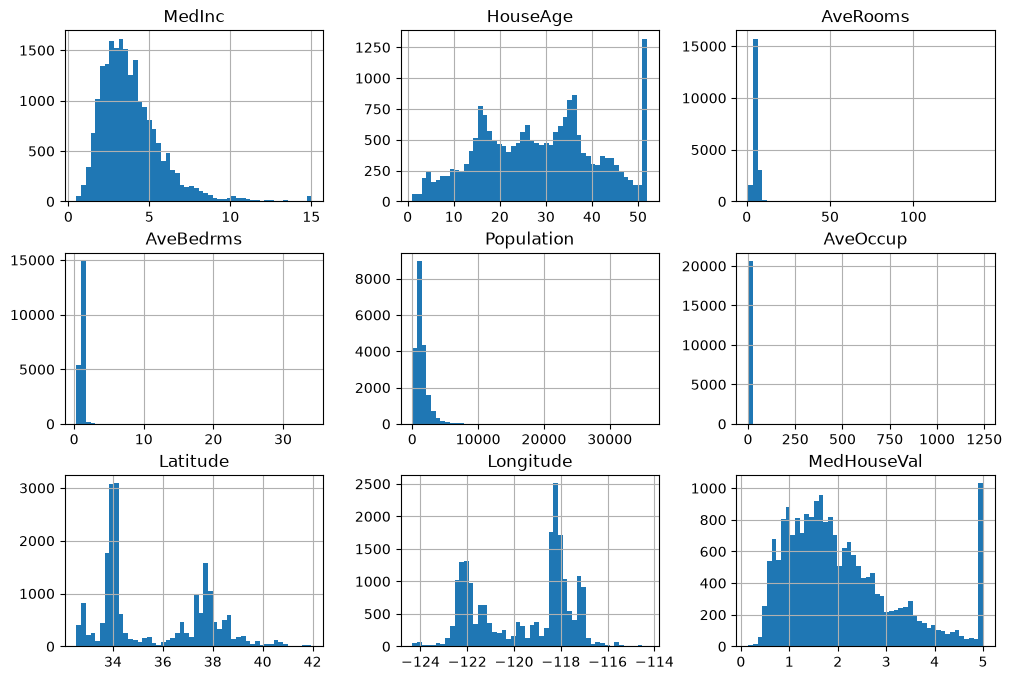

In [4]:
# Display the first few rows
print("Dataset Overview:")
print(df.head())
print(df.info())

df.hist(bins=50, figsize=(12, 8))
plt.show()

## Question 1 (30 pts）
- Can you figure out what these headers mean?
- From these graph, what would be the features that could predict the house value?

Enter your answers in the following cell

In [5]:
# 1. Each of the headers represent the distribution of each feature of the California housing dataset, it provides the range and frequency of values for each feature. For example, MedInc shows the distribution of median income of household in the dataset, while MedHouseVal shows the distribution of median house values. The histograms help us understand the characteristics of the data, identify the outliers of each features, and any skewed distributions. Further header meanings: House Age shows the distribution of age of houses, AveRooms shows the distribution of rooms per household, AveBedrms shows the distribution of bedrooms per household, Population shows the distribution of total population of the dataset, AveOccup shows the distribution of the average number of people, Latitude shows the distribution of geographical latitude, and Longitude shows the distribution of geographical longitude.
# 2. These histograms show the distribution of each variable independently. They do not show the relationship between a feature and MedHouseVal. Therefore, we cannot determine with certainty which features are predictive using these graphs alone. However, based on the feature meanings, we can identify several reasonable candidates:
# - MedInc is likely to be the strongest predictor. Areas with higher median household income often have higher house values.
# - Latitude and Longitude are likely to be important when used together because house values depend strongly on location. They can capture differences between coastal, inland, urban, and rural areas.
# - AveRooms may be useful because the average number of rooms may reflect housing size and local wealth.
# - HouseAge may also contribute because housing age can be related to location, neighbourhood development, and property value.
# - AveBedrms, Population, and AveOccup may provide additional information, but they may be weaker predictors when considered individually.
# Hence from the histograms, the most promising features are: MedInc, Latitude and Longitude together, AveRooms, and HouseAge

## Exercise 2: Train a linear regression model

Mean Squared Error: 0.53
R-squared: 0.60


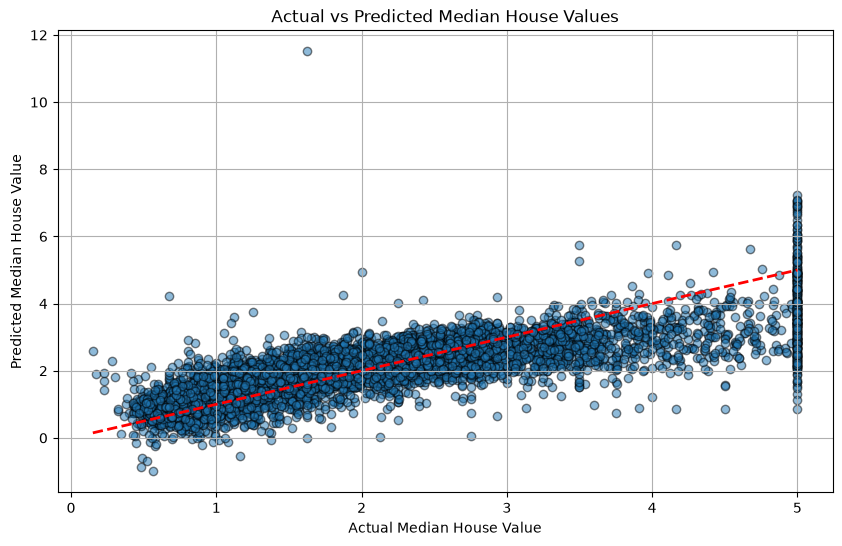


Feature Importance:
      Feature   Coefficient
3   AveBedrms  7.785996e-01
0      MedInc  4.458226e-01
1    HouseAge  9.681868e-03
4  Population -7.757404e-07
5    AveOccup -3.370027e-03
2    AveRooms -1.220951e-01
6    Latitude -4.185367e-01
7   Longitude -4.336880e-01


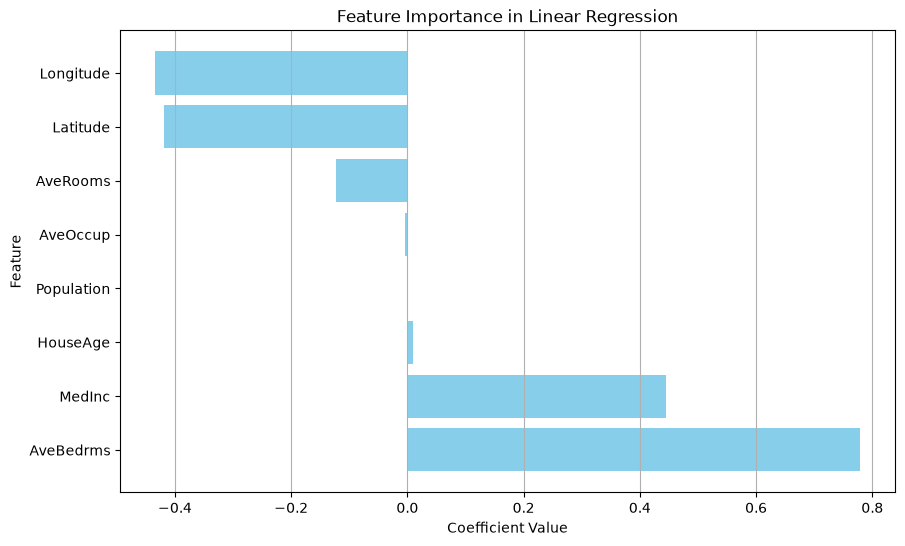

In [6]:
# Features and target
X = df.drop(columns=["MedHouseVal"])  # Features
y = df["MedHouseVal"]  # Target (Median House Value)

# Step 2: Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 3: Fit a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 4: Make predictions
y_pred = model.predict(X_test)

# Step 5: Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

# Step 6: Plot actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted Median House Values")
plt.grid()
plt.show()

# Step 7: Feature importance (coefficients)
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values(by="Coefficient", ascending=False)

print("\nFeature Importance:")
print(coefficients)

# Step 8: Visualize feature importance
plt.figure(figsize=(10, 6))
plt.barh(coefficients["Feature"], coefficients["Coefficient"], color='skyblue')
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Feature Importance in Linear Regression")
plt.grid(axis='x')
plt.show()

## Question 2 (30 pts)
- What did you see?
- What are the important features?

In [7]:
# 1. R^2 = 0.6 means the model explains around 60% of the variation in median house value in the test set.
# 2. The coefficients indicate the relationship between each feature. A positive coefficient means that increasing the feature is associated with an increase in predicted house value, while a negative coefficient indicates the opposite. So the important features that could help predict MedHouseVal is MedInc and AveBedrms because they have higher correlations with the MedHouseVal. Since we have different units for each feature, we can normalize the dataset before we create the correlation plot, such that we can obtain a more accurate result.

Mean Squared Error: 0.53
R-squared: 0.60


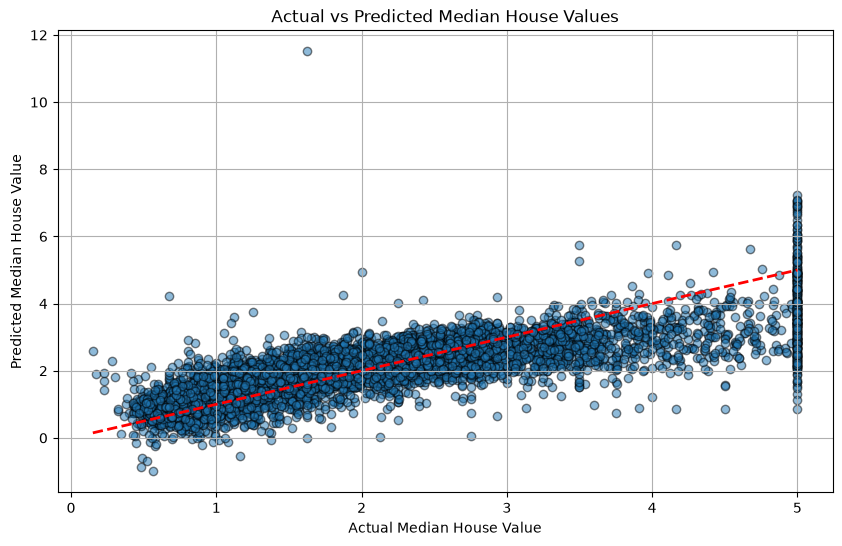


Feature Importance:
      Feature  Coefficient
0      MedInc     0.849222
3   AveBedrms     0.348410
1    HouseAge     0.122119
4  Population    -0.000884
5    AveOccup    -0.041698
2    AveRooms    -0.299558
7   Longitude    -0.868617
6    Latitude    -0.893856


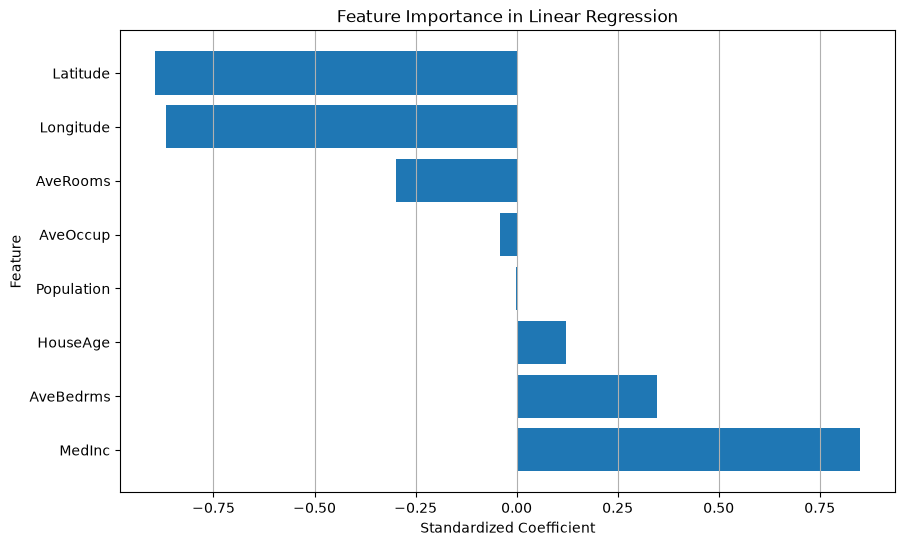

In [8]:
# Doing the same steps but I normalize the dataset first this time
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted Median House Values")
plt.grid()
plt.show()

coefficients = pd.DataFrame({
  "Feature": X.columns,
  "Coefficient": model.coef_
}).sort_values(by="Coefficient", ascending=False)

print("\nFeature Importance:")
print(coefficients)

plt.figure(figsize=(10, 6))
plt.barh(
  coefficients["Feature"],
  coefficients["Coefficient"]
)
plt.xlabel("Standardized Coefficient")
plt.ylabel("Feature")
plt.title("Feature Importance in Linear Regression")
plt.grid(axis='x')
plt.show()

In [9]:
# After standardization, MedInc have the largest absolute coefficient, while Longitude and Latitude has the smallest absolute coefficients. This suggests that geographical location and median income make the strongest contributions to this linear model. AveRooms and AveBedrms have moderate contributions, while Population and AveOccup have relatively small contributions.

## Exercise 3: feature engineering

Below is an example where we chose longitude and latitude as the features to predict median house value. Note that the visualization highlights the geographical distribution of house values, which provides insights into how location influences housing prices. While the model may capture spatial trends, the prediction accuracy might be limited since other factors like income or population density are not included.

Mean Squared Error: 0.99
R-squared: 0.25


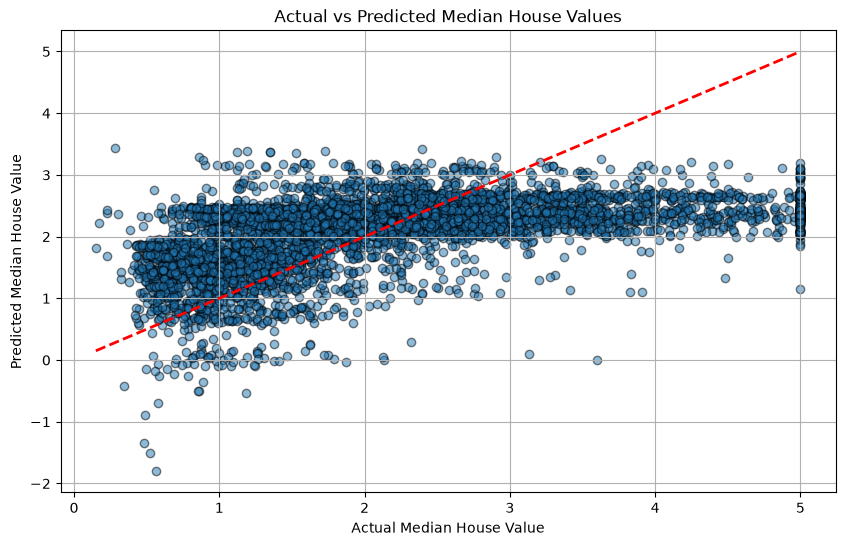

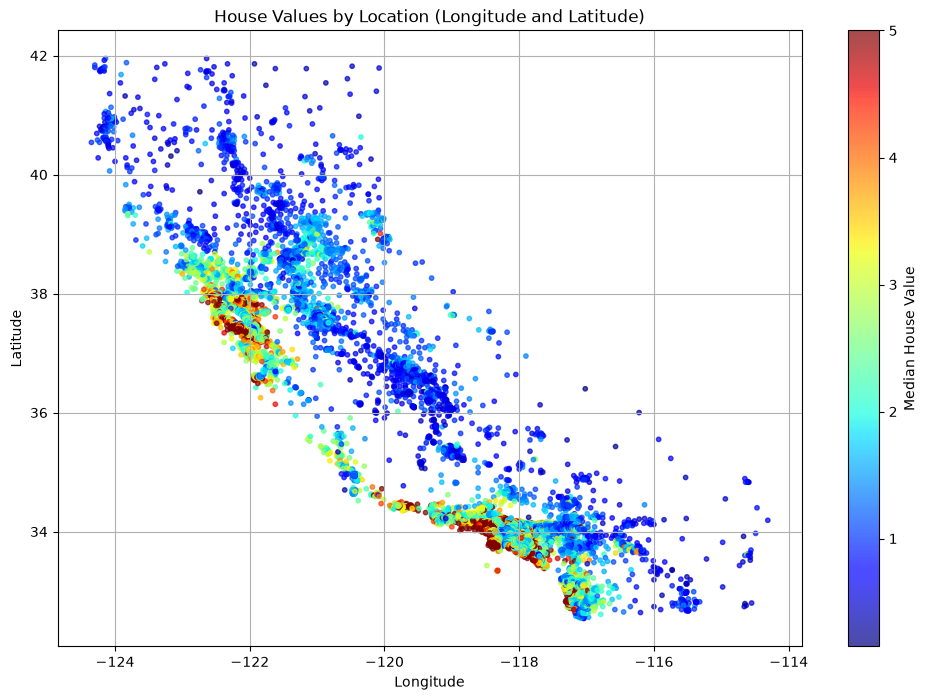

In [10]:
# Use only longitude and latitude as features
X = df[["Longitude", "Latitude"]]
y = df["MedHouseVal"]  # Target (Median House Value)

# Step 2: Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 3: Fit a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 4: Make predictions
y_pred = model.predict(X_test)

# Step 5: Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

# Step 6: Visualize predictions on a scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted Median House Values")
plt.grid()
plt.show()

# Step 7: Visualize Longitude, Latitude, and House Value
plt.figure(figsize=(12, 8))
plt.scatter(X["Longitude"], X["Latitude"], c=y, cmap="jet", s=10, alpha=0.7)
plt.colorbar(label="Median House Value")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("House Values by Location (Longitude and Latitude)")
plt.grid()
plt.show()

It’s your turn now! Copy the cell above, modify the code and pick different features. Compare the results you obtain, and visualize the features in interesting ways. Explain your findings and discuss the results.

Mean Squared Error: 0.62
R-squared: 0.53


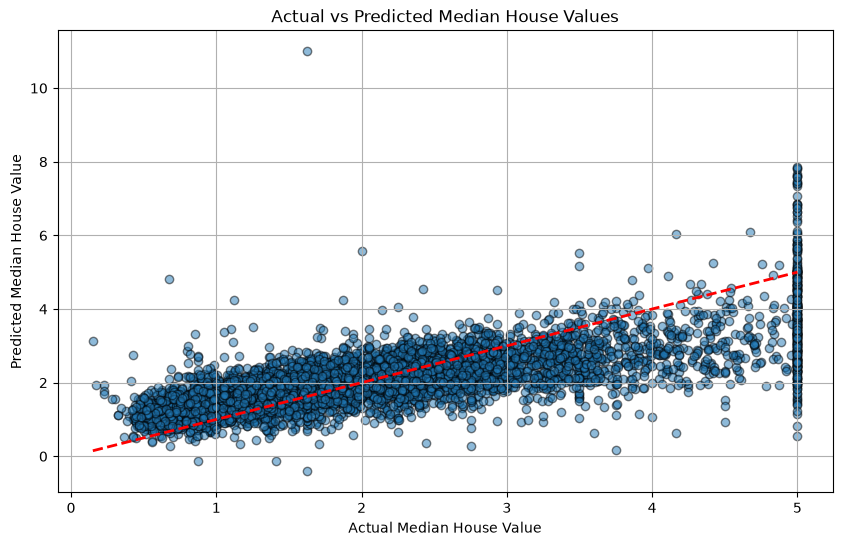

In [11]:
# Features and target 
##########################################
# PRACTICE: pick different features here #
##########################################
X = df.drop(columns=["MedHouseVal", "Longitude", "Latitude"])  # Features
y = df["MedHouseVal"]  # Target (Median House Value)

# Step 2: Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Step 3: Fit a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 4: Make predictions
y_pred = model.predict(X_test)

# Step 5: Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

# Step 6: Plot actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted Median House Values")
plt.grid()
plt.show()

Mean Squared Error: 0.69
R-squared: 0.47


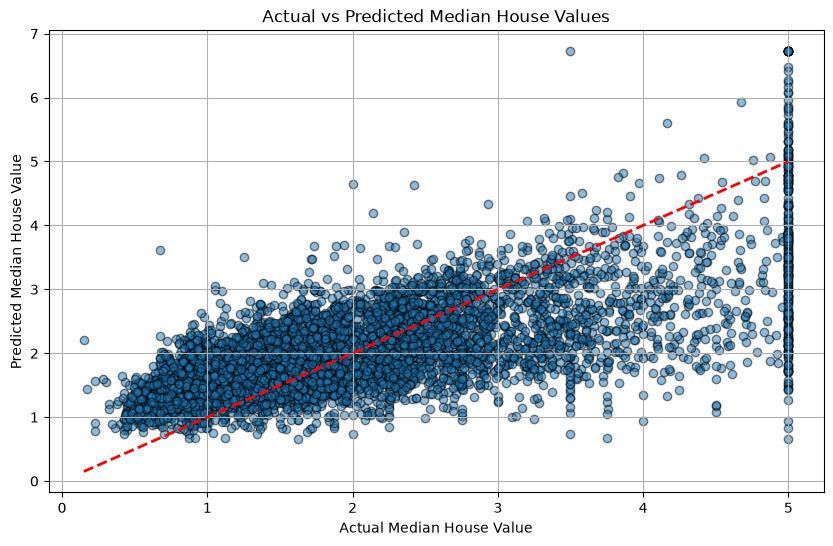

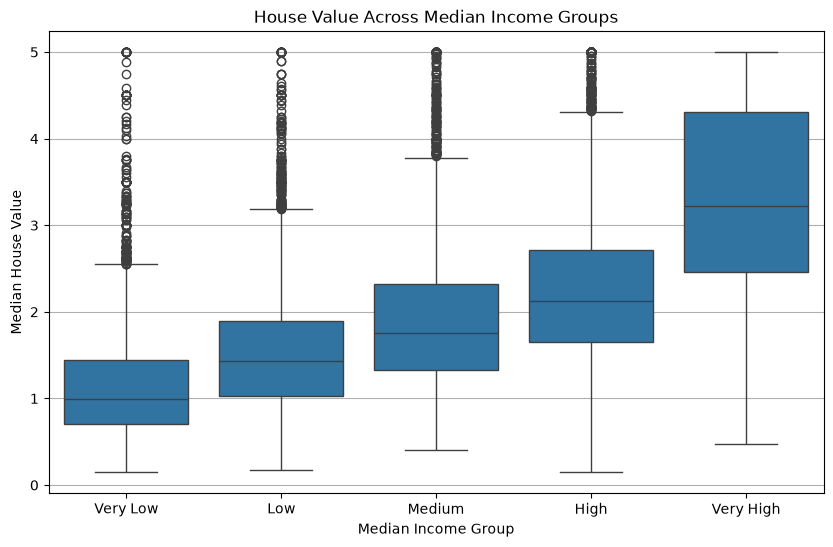

In [12]:
# Use only median income value as a feature
X = df[["MedInc"]]
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

# scatter plot of median income value vs median house value
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted Median House Values")
plt.grid()
plt.show()

# boxplots of median income value vs median house value
df["IncomeGroup"] = pd.qcut(
    df["MedInc"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"]
)
plt.figure(figsize=(10, 6))
sns.boxplot(
    x="IncomeGroup",
    y="MedHouseVal",
    data=df
)
plt.xlabel("Median Income Group")
plt.ylabel("Median House Value")
plt.title("House Value Across Median Income Groups")
plt.grid(axis="y")
plt.show()

Mean Squared Error: 1.11
R-squared: 0.16


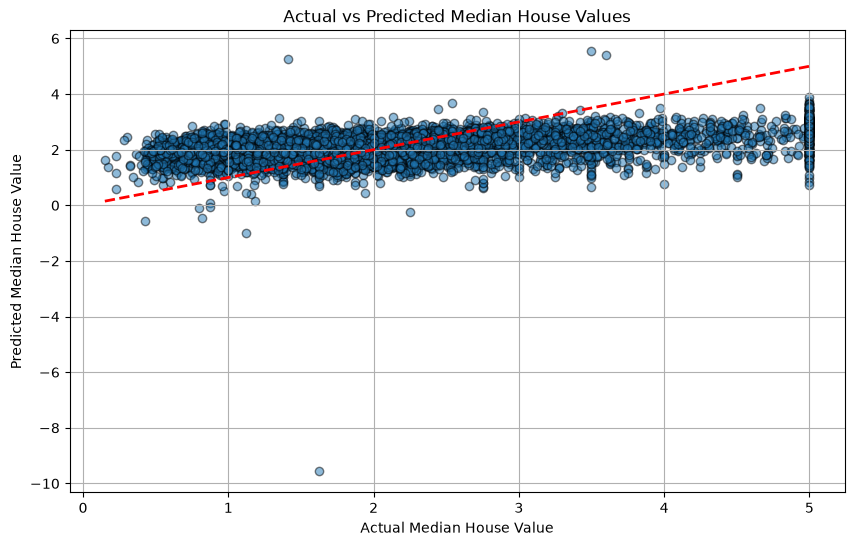

In [13]:
# Use AveBedrms and AveRooms value as a feature - grouping them based on the number of rooms
X = df[["AveBedrms", "AveRooms", "HouseAge"]]
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

# scatter plot of median income value vs median house value
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted Median House Values")
plt.grid()
plt.show()

Mean Squared Error: 0.64
R-squared: 0.51


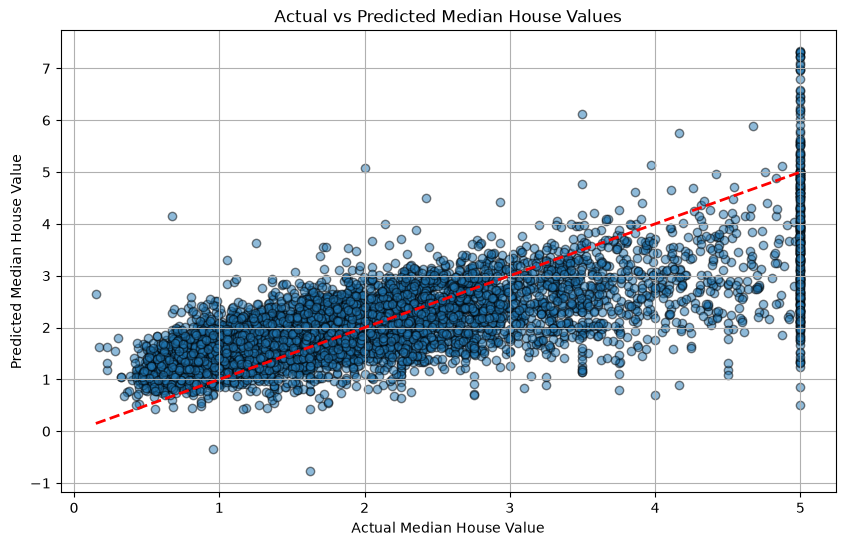

In [ ]:
X = df[["MedInc", "HouseAge", "AveRooms", "AveOccup"]]
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.3, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

# Step 6: Plot actual vs. predicted values

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolor="k")
plt.plot(
  [y_test.min(), y_test.max()],
  [y_test.min(), y_test.max()],
  "r--",
  linewidth=2
)

plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs Predicted Median House Values")
plt.grid()
plt.show()


## Question 3.1

Try creating the plots below

- Visualize the relationship between features and house value
- Scatter plot for Median Income vs House Value
- Scatter plot for AveBedrms vs House Value
- Create one visualisation that is different from all the above

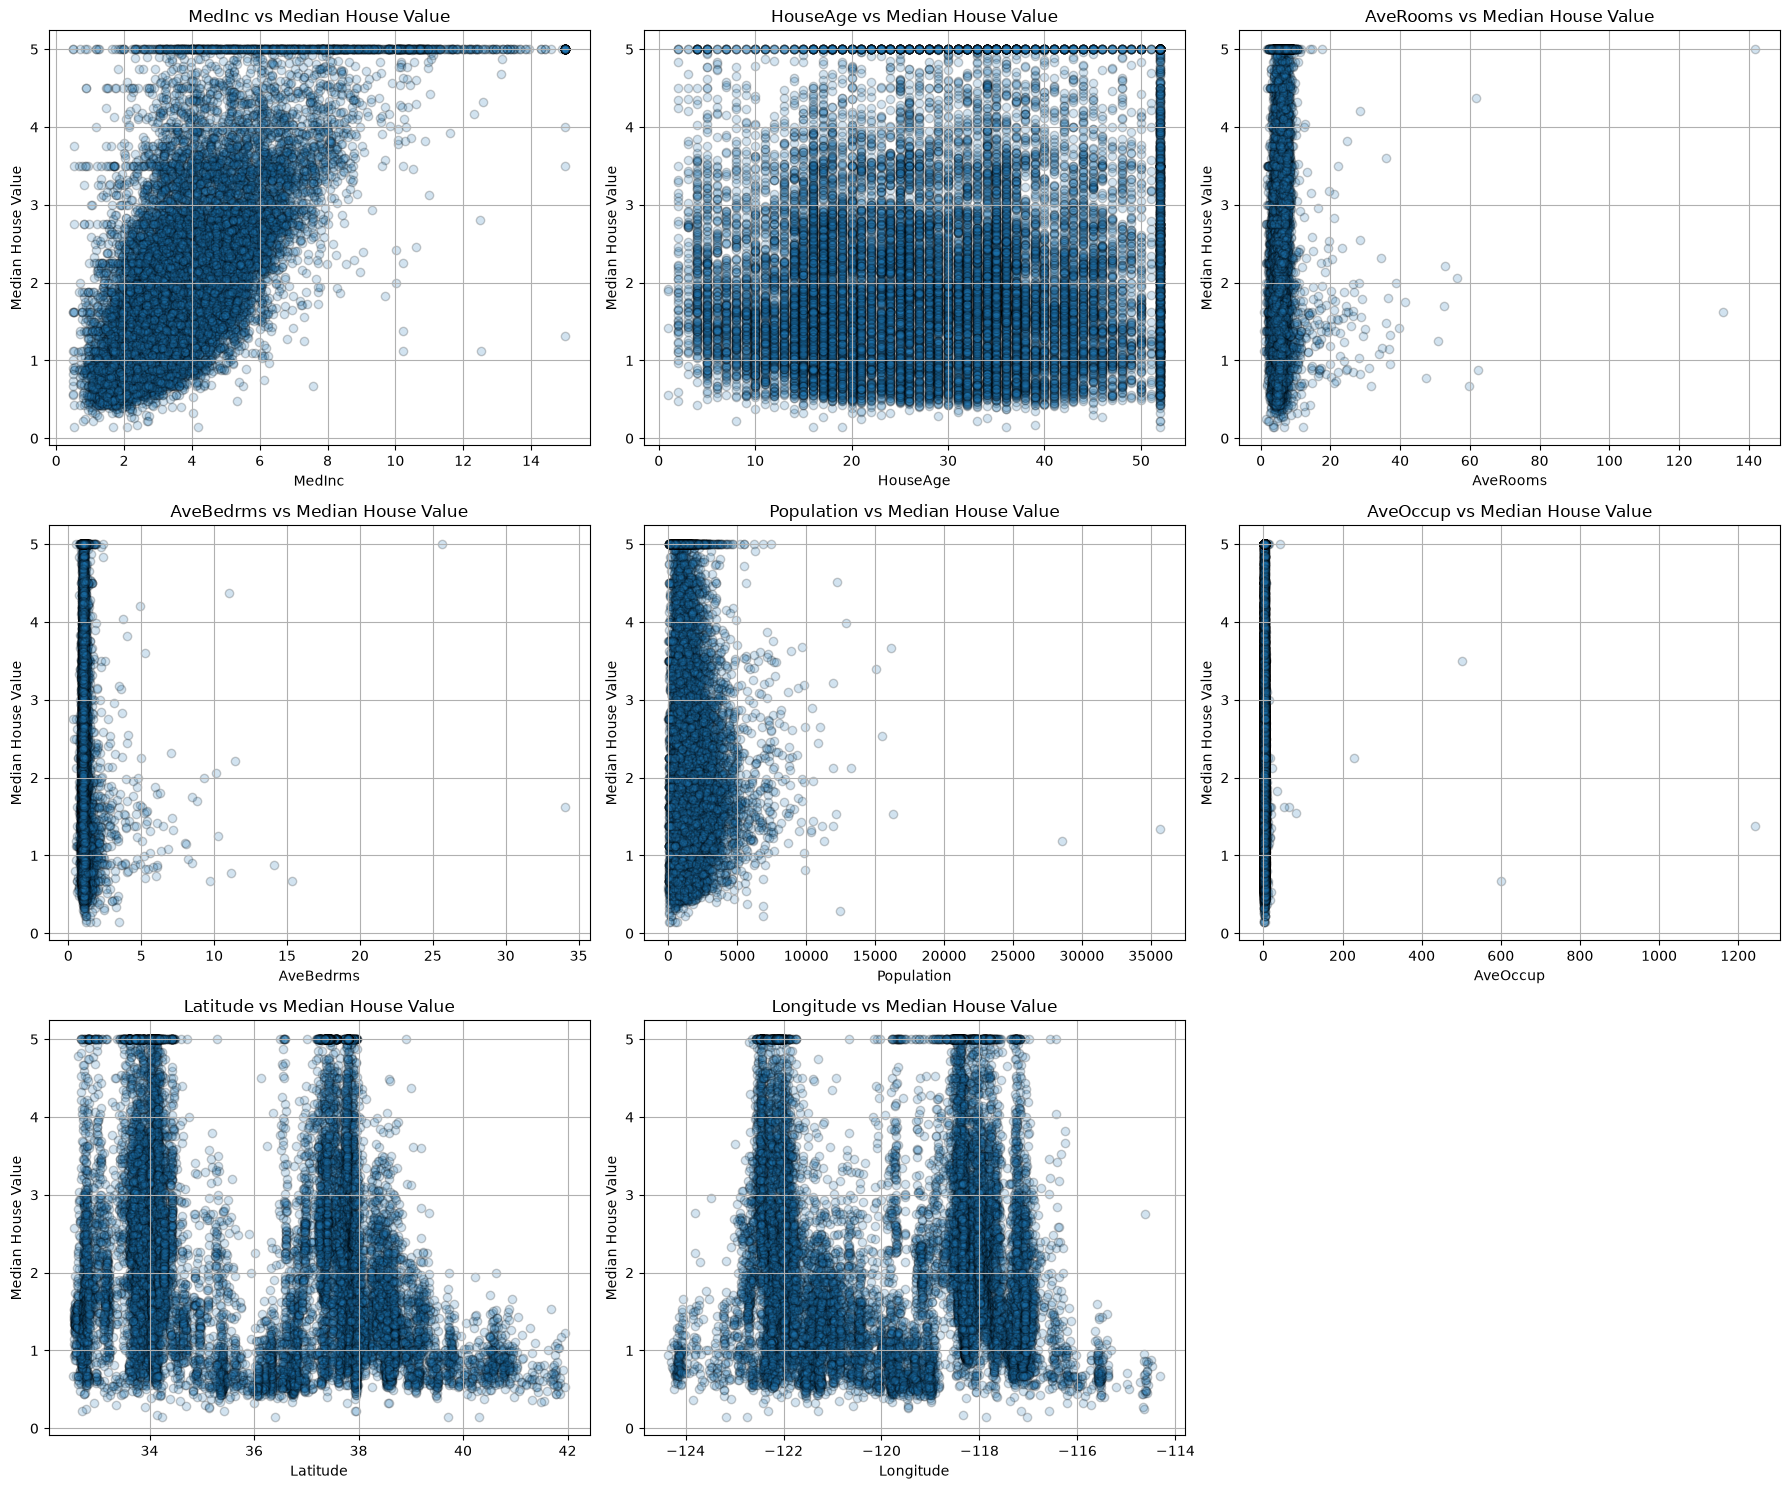

In [16]:
features = df.drop(columns=["MedHouseVal", "IncomeGroup"]).columns

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, feature in enumerate(features):
  axes[i].scatter(
    df[feature],
    df["MedHouseVal"],
    alpha=0.2,
    edgecolor="k"
  )

  axes[i].set_xlabel(feature)
  axes[i].set_ylabel("Median House Value")
  axes[i].set_title(f"{feature} vs Median House Value")
  axes[i].grid()

axes[8].set_visible(False)
plt.tight_layout()
plt.show()

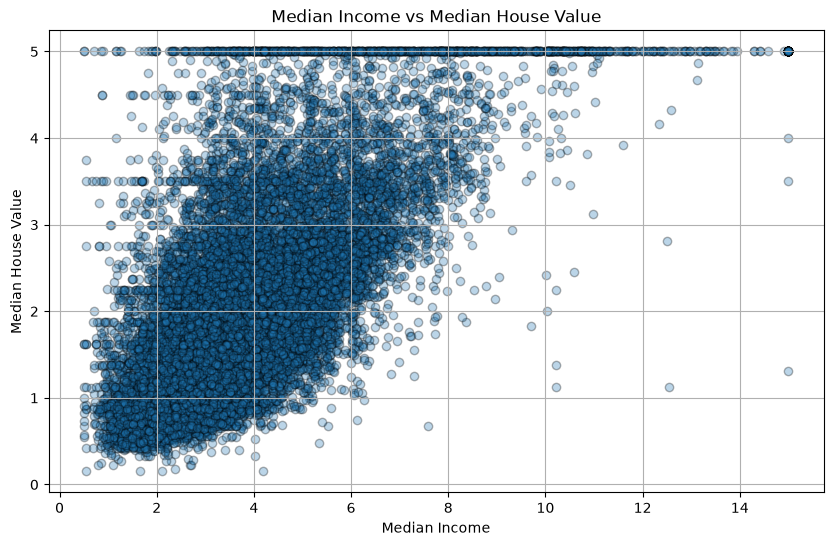

In [17]:
# median income vs house value
plt.figure(figsize=(10, 6))
plt.scatter(
    df["MedInc"],
    df["MedHouseVal"],
    alpha=0.3,
    edgecolor="k"
)
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Median Income vs Median House Value")
plt.grid()
plt.show()

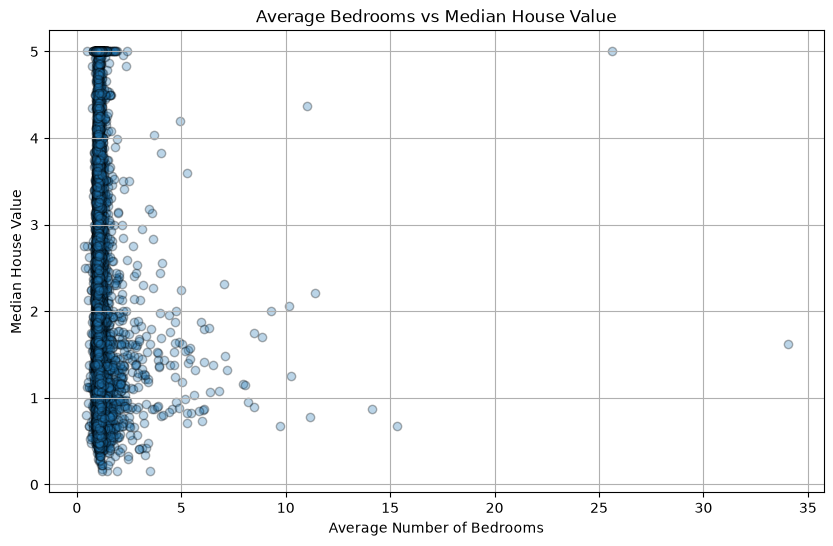

In [ ]:
# average bedrooms vs house value
plt.figure(figsize=(10, 6))
plt.scatter(
  df["AveBedrms"],
  df["MedHouseVal"],
  alpha=0.3,
  edgecolor="k"
)
plt.xlabel("Average Number of Bedrooms")
plt.ylabel("Median House Value")
plt.title("Average Bedrooms vs Median House Value")
plt.grid()
plt.show()

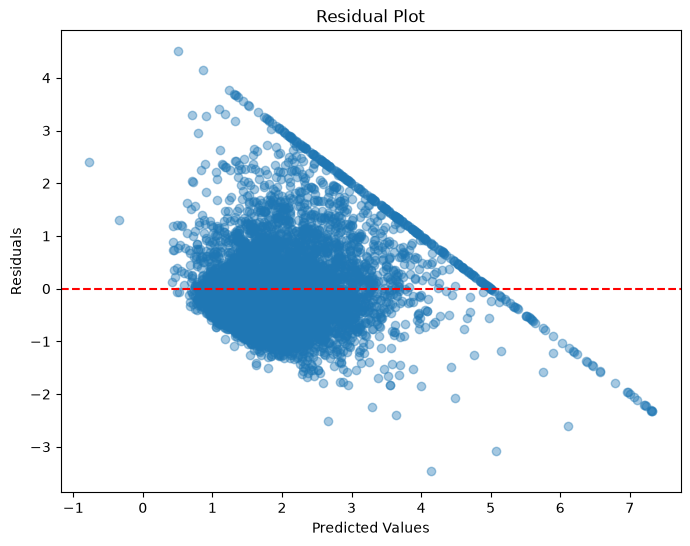

In [18]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [ ]:
# It seems that the residual plot against the predicted value shows that they're following a specific pattern.

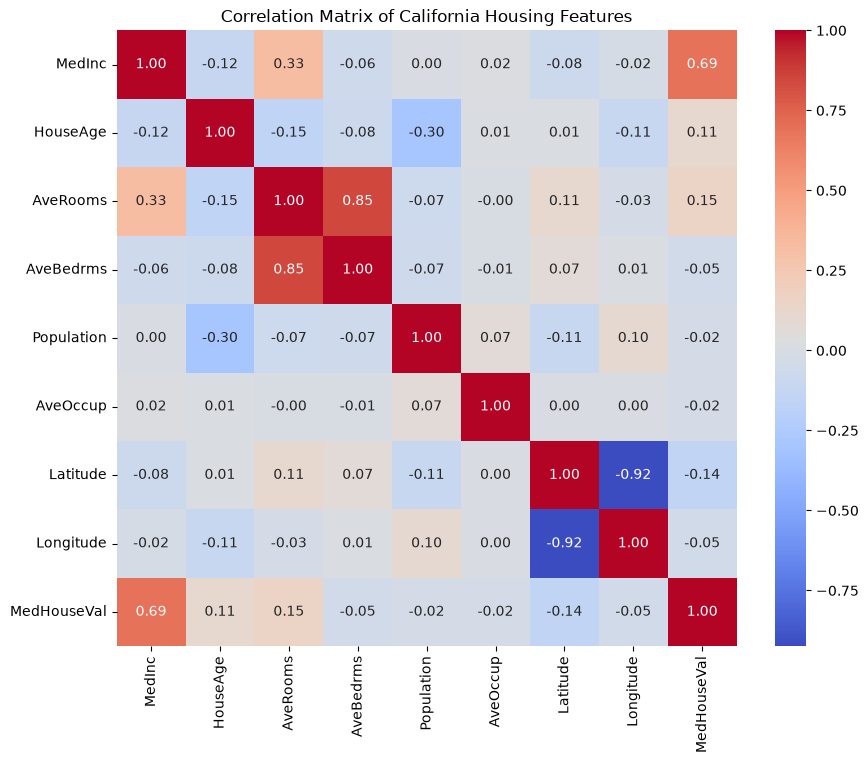

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of California Housing Features")
plt.show()

In [ ]:
# From the correlation heatmap above, the strongest individual positive predictors is MedInc. While the strongest individual negative predictor is the latitude.

## Questions 3.2
- Which features you chose and why? What information does it convey? Why is it better?

In [ ]:
# I selected the following six features: MedInc, Latitude, Longitude, AveRooms, AveBedrms, and HouseAge. These features represent several different aspects of the housing market. For instance, MedInc represents the economic conditions and household purchasing power, Latitude and Longitude represents the geographical location of the households, and AveRooms represents the approximate housing size. I did not include Population and AveOccup because the earlier analysis showed that they made relatively small contributions to this linear model.
# MedInc was selected because it had the strongest individual positive relationship with house value. The income scatter plot and grouped bar chart both showed that house values generally increased as median income increased. Latitude and Longitude were selected together because they identify geographical location. Although their individual correlations with house value were not particularly strong, their combination can capture broad differences between coastal, inland, urban, and rural areas. AveRooms, AveBedrms, and HouseAge were selected because they provide information about housing characteristics that income and location do not describe.
# The visualizations showed that: MedInc has a clear positive relationship with MedHouseVal, AveBedrms has a weak relationship with house value when considered by itself, house-value distributions overlap considerably across most house-age groups, the highest-income group has a substantially higher median house value than the lowest-income group. No single feature can fully explain house value, so combining economic, geographical, and housing information is more appropriate.